# Figuras para la sección 4 · resultados individuales e integrados

Esta libreta reúne relevancia, sentimiento histórico, estructura de tópicos, ejemplos con sentimiento e interpretación LLM. Lee exportaciones verificadas y los análisis guardados. No entrena modelos ni solicita interpretaciones.

La comparación integrada contiene 1.000 reseñas base y 987 alternativas. Las pruebas de relevancia y sentimiento usan otras referencias. Las 46 interpretaciones se ejecutaron por separado el 7 de noviembre de 2026; aquí se verifican y presentan las respuestas guardadas, incluyendo sus límites semánticos. Reejecutar esta libreta no genera cargos.

In [1]:
from pathlib import Path
from dataclasses import asdict
import sys, json, textwrap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown
REPO=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/voc').is_dir())
NB_ROOT=REPO/'reports/drafts/difusion'
if str(NB_ROOT) not in sys.path:sys.path.insert(0,str(NB_ROOT))
from apoyo_validacion import digest, export_bundle, ranked_sample, show_texts
from apoyo_revision import verified_bundle
from voc.analysis.store import read_analysis
from voc_ml.experiments.operations import load_protocol
from voc.paths import data_root
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
BLUE='#32698b';ORANGE='#d77a49'
LABELS=['negative','neutral','positive']
NAMES={'negative':'Negativo','neutral':'Neutral','positive':'Positivo'}
COLORS={'negative':'#b94948','neutral':'#a6adb3','positive':'#40846b'}
SYSTEMS={'base':'Base','alternative':'Alternativa'}
specs={
 'relevancia':('exports/evaluacion-filtro-relevancia/20261105T191417687054Z','650e866d27c4ed0b0cccee1a9b6ae4823668894a5db5567ccde5fb474e419df9'),
 'historico':('exports/evaluacion-historica-robertuito/20261105T191415696114Z','30615f09a5d231445e261bcc68d46a23e4f7b0c9220ad1e1870e289da443321a'),
 'integrada':('exports/comparacion-base-alternativa/20261105T191417975479Z','4639edacc5839af99fe7121921f29e9183b320e0b5354f5090570248f3f788d1')}
bundles={name:verified_bundle(NB_ROOT,*spec) for name,spec in specs.items()}
sources={name:{'path':str((p/'manifest.json').relative_to(REPO)),'sha256':digest(p/'manifest.json')} for name,p in bundles.items()}
figures={};tables={};payloads={}

## 1. Relevancia: métricas y costo de los errores

Mismos 160 textos, predicciones de validación fuera del entrenamiento de cada partición. La elección del clasificador usa esta validación: no es una prueba independiente posterior. Mostramos el control por plataforma junto a los modelos.

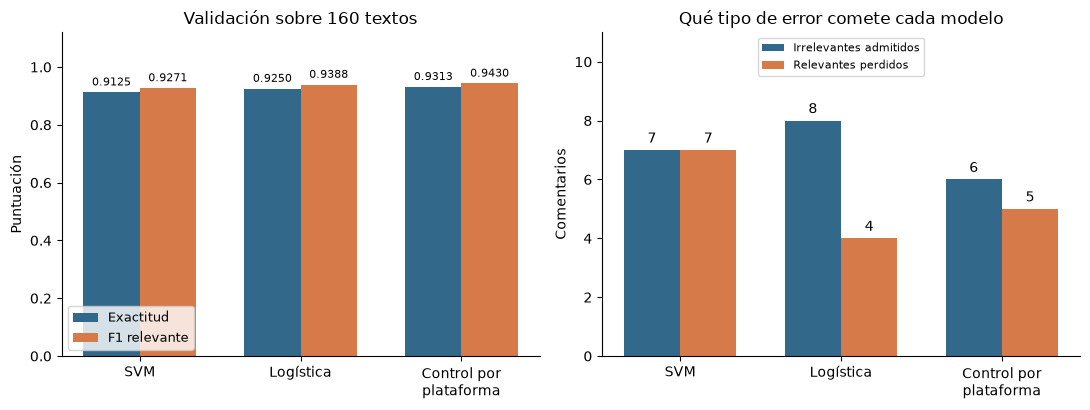

In [2]:
relevance=pd.read_csv(bundles['relevancia']/'metricas-oof.csv')
fig,axes=plt.subplots(1,2,figsize=(11,4.2))
x=np.arange(len(relevance));w=.35
for offset,col,label,color in [(-w/2,'accuracy','Exactitud',BLUE),(w/2,'f1_relevant','F1 relevante',ORANGE)]:
 bars=axes[0].bar(x+offset,relevance[col],width=w,label=label,color=color)
 axes[0].bar_label(bars,fmt='%.4f',fontsize=8,padding=3)
axes[0].set(xticks=x,xticklabels=['SVM','Logística','Control por\nplataforma'],ylim=(0,1.12),ylabel='Puntuación',title='Validación sobre 160 textos');axes[0].legend(loc='lower left',fontsize=9)
for offset,col,label,color in [(-w/2,'irrelevant_passed','Irrelevantes admitidos',BLUE),(w/2,'relevant_lost','Relevantes perdidos',ORANGE)]:
 bars=axes[1].bar(x+offset,relevance[col],width=w,label=label,color=color)
 axes[1].bar_label(bars,padding=3)
axes[1].set(xticks=x,xticklabels=['SVM','Logística','Control por\nplataforma'],ylim=(0,11),ylabel='Comentarios',title='Qué tipo de error comete cada modelo');axes[1].legend(loc='upper center',fontsize=8)
axes[0].set_yticks(np.arange(0,1.01,.2))
fig.tight_layout();plt.show();figures['relevancia-comparada']=fig;tables['relevancia-metricas']=relevance

## 2. Robertuito: evaluación histórica

Resultados del entrenamiento previo sobre 14.438 reseñas de tiendas con referencia derivada de estrellas. La figura usa «Con transfer learning»; el identificador del checkpoint queda en las fuentes. La clase neutral tiene soporte 936, frente a 3.238 negativos y 10.264 positivos. Esta prueba no evalúa nuestra nueva muestra ni demuestra transferencia a redes sociales.

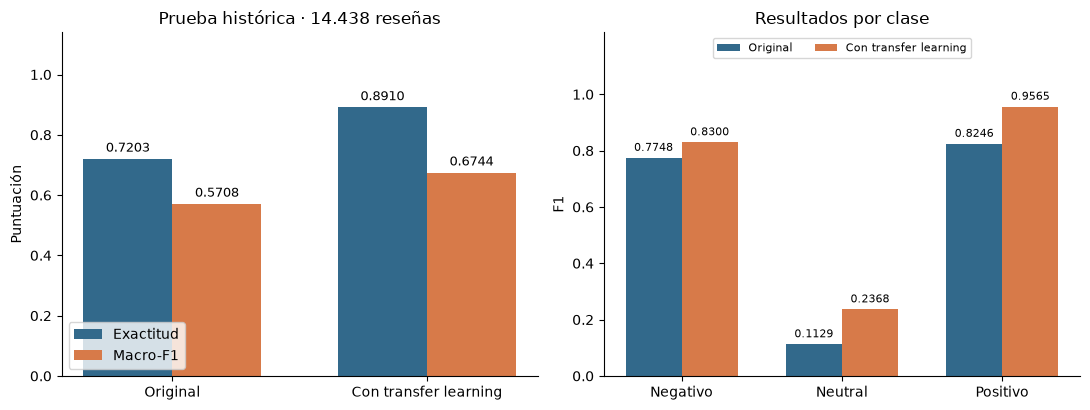

In [3]:
aggregate=pd.read_csv(bundles['historico']/'metricas-agregadas.csv')
classes=pd.read_csv(bundles['historico']/'metricas-por-clase.csv')
fig,axes=plt.subplots(1,2,figsize=(11,4.2))
x=np.arange(2);w=.35
for offset,col,label,color in [(-w/2,'accuracy','Exactitud',BLUE),(w/2,'macro_f1','Macro-F1',ORANGE)]:
 bars=axes[0].bar(x+offset,aggregate[col],width=w,label=label,color=color);axes[0].bar_label(bars,fmt='%.4f',padding=3,fontsize=9)
axes[0].set(xticks=x,xticklabels=['Original','Con transfer learning'],ylim=(0,1.14),ylabel='Puntuación',title='Prueba histórica · 14.438 reseñas');axes[0].legend(loc='lower left')
x=np.arange(3)
for offset,model,label,color in [(-w/2,'Original','Original',BLUE),(w/2,'Tiendas v3','Con transfer learning',ORANGE)]:
 values=classes.loc[classes.model.eq(model)].set_index('label').loc[LABELS,'f1-score']
 bars=axes[1].bar(x+offset,values,width=w,label=label,color=color);axes[1].bar_label(bars,fmt='%.4f',padding=3,fontsize=8)
axes[1].set(xticks=x,xticklabels=[NAMES[l] for l in LABELS],ylim=(0,1.22),ylabel='F1',title='Resultados por clase');axes[1].legend(loc='upper center',fontsize=8,ncol=2)
axes[0].set_yticks(np.arange(0,1.01,.2))
axes[1].set_yticks(np.arange(0,1.01,.2))
fig.tight_layout();plt.show();figures['sentimiento-historico']=fig;tables.update({'sentimiento-historico-agregado':aggregate,'sentimiento-historico-clases':classes})

## 3. Agrupamiento: concentración y cobertura

Los puntos del panel izquierdo se ordenan por tamaño dentro de cada sistema; la posición horizontal no empareja tópicos entre modelos. El grupo −1 queda fuera de esos tamaños y se cuenta como reseñas sin asignar en el panel derecho. Los porcentajes tienen denominadores diferentes: 1.000 y 987.

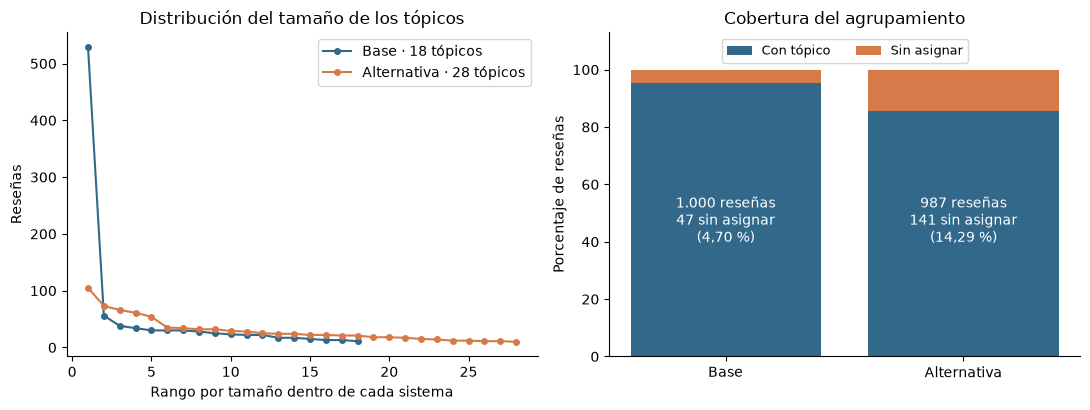

In [4]:
structure=pd.read_csv(bundles['integrada']/'topicos-resumen.csv')
all_topics={s:pd.read_csv(bundles['integrada']/f"topicos-{'base' if s=='base' else 'alternativa'}.csv") for s in SYSTEMS}
fig,axes=plt.subplots(1,2,figsize=(11,4.2))
for system,color in [('base',BLUE),('alternative',ORANGE)]:
 values=all_topics[system].sort_values(['size','topic_id'],ascending=[False,True])['size']
 axes[0].plot(range(1,len(values)+1),values,'o-',label=f'{SYSTEMS[system]} · {len(values)} tópicos',color=color,markersize=4)
axes[0].set(xlabel='Rango por tamaño dentro de cada sistema',ylabel='Reseñas',title='Distribución del tamaño de los tópicos');axes[0].legend()
x=np.arange(2);unassigned=structure.unassigned_pct.to_numpy()
axes[1].bar(x,100-unassigned,color=BLUE,label='Con tópico');axes[1].bar(x,unassigned,bottom=100-unassigned,color=ORANGE,label='Sin asignar')
for i,row in structure.iterrows():
 axes[1].text(i,40,f'{int(row.rows):,} reseñas'.replace(',','.')+f'\n{int(row.unassigned)} sin asignar\n({row.unassigned_pct:.2f} %)'.replace('.',','),ha='center',color='white')
axes[1].set(xticks=x,xticklabels=[SYSTEMS[s] for s in structure.system],ylim=(0,113),ylabel='Porcentaje de reseñas',title='Cobertura del agrupamiento');axes[1].legend(loc='upper center',ncol=2,fontsize=9)
fig.tight_layout();plt.show();figures['agrupamiento-comparado']=fig;tables['agrupamiento-resumen']=structure

## 4. Ejemplos integrados: tres tópicos mayores por sistema

Elegimos los tres grupos mayores, con desempate por topic_id. Mostramos las seis primeras palabras clave y la distribución completa de sentimiento por reseña dentro de cada grupo. Cada tarjeta de la figura incluye un fragmento de una reseña elegida por orden SHA-256 con semilla 42; no se selecciona por su tono ni por parecer representativa. El fragmento se limita a 190 caracteres y se marca cuando está recortado. Debajo se conservan hasta tres textos distintos completos por grupo, con IDs y etiquetas.

Los grupos situados en la misma fila no son parejas equivalentes. El sentimiento se predice sobre toda la reseña; no se atribuye específicamente a cada funcionalidad mencionada. Los IDs de tópico son locales a cada sistema.

In [5]:
ROOT=data_root()/'experiments/julaug-2026'
protocol=load_protocol(ROOT)
runs={s:json.loads((ROOT/f'{s}-run.json').read_text()) for s in SYSTEMS}
frames={};analyses={};cases=[];counts=[]
for system,run in runs.items():
 assert run['state']=='completed' and run['representation']['tracking_verified']
 saved=read_analysis(run['representation']['analysis_id']);analyses[system]=saved
 frame=saved.reviews.merge(pd.DataFrame([asdict(a) for a in saved.assignments]),on='record_id',validate='one_to_one').merge(pd.DataFrame([asdict(a) for a in saved.sentiments]),on='record_id',validate='one_to_one')
 assert frame.status.eq('classified').all()
 assert set(frame.model_label)<=set(LABELS)
 frames[system]=frame
 expected=structure.loc[structure.system.eq(system)].iloc[0]
 assert len(frame)==int(expected.rows)
 assert frame.loc[frame.topic_id.ge(0),'topic_id'].nunique()==int(expected.topics)
 assert int(frame.topic_id.eq(-1).sum())==int(expected.unassigned)
 topic_map={t.topic_id:t for t in saved.topics}
 ranked=frame.loc[frame.topic_id.ge(0)].groupby('topic_id').size().rename('size').reset_index().sort_values(['size','topic_id'],ascending=[False,True]).head(3)
 for rank,row in enumerate(ranked.itertuples(),1):
  members=frame.loc[frame.topic_id.eq(row.topic_id)]
  sentiment=members.model_label.value_counts().reindex(LABELS,fill_value=0)
  assert int(sentiment.sum())==row.size
  examples=ranked_sample(members,3,f'section4-examples-v1:42:{system}:{row.topic_id}',distinct_text=True)
  case={'system':system,'analysis_id':run['representation']['analysis_id'],'topic_id':int(row.topic_id),'rank':rank,'size':int(row.size),
        'keywords':[k.term for k in topic_map[row.topic_id].keywords],
        'sentiment':{label:int(sentiment[label]) for label in LABELS},
        'reviews':examples[['record_id','platform','model_text','model_label']].to_dict('records')}
  cases.append(case)
  counts.append({'system':system,'topic_id':int(row.topic_id),'rank':rank,'size':int(row.size),**case['sentiment']})
 path=data_root()/'analyses'/run['representation']['analysis_id']/'manifest.json'
 sources[system+'_analysis']={'path':str(path.relative_to(REPO)),'sha256':digest(path)}
summary=pd.DataFrame(counts);display(summary)
for case in cases:
 display(Markdown(f"### {SYSTEMS[case['system']]} · tópico {case['topic_id']} · {case['size']} reseñas"))
 display(Markdown('**Palabras clave:** '+', '.join(case['keywords'])))
 show_texts(case['reviews'])

,system,topic_id,rank,size,negative,neutral,positive
0,base,0,1,529,459,65,5
1,base,1,2,56,0,55,1
2,base,2,3,38,0,8,30
3,alternative,0,1,105,81,14,10
4,alternative,1,2,73,55,9,9
5,alternative,2,3,66,55,4,7


### Base · tópico 0 · 529 reseñas

**Palabras clave:** app, aplicación, no abre, tarjeta, banamex, abrir, no puedo, abre, no deja, puedo

### Base · tópico 1 · 56 reseñas

**Palabras clave:** excelentes excelente, perfeccion excelente, excelente siempre, siempre excelentes, tal perfeccion, perfeccion, seria perfecto, perfecto no, existe tal, no existe

### Base · tópico 2 · 38 reseñas

... (3 outputs left out)

### Alternativa · tópico 1 · 73 reseñas

**Palabras clave:** tarda mucho, no deja, tener esperar, abre tarda, 15 días, cualquier hora, mucho abrir, nunca abre, algunas veces, movimientos no

### Alternativa · tópico 2 · 66 reseñas

**Palabras clave:** app banco, app tarda, aplicación banco, banca móvil, bancaria, banca, otros bancos, entrar banca, acceso, hacer transferencias

/tmp/ipykernel_1761/4136599012.py:23: UserWarning: Glyph 128078 (\N{THUMBS DOWN SIGN}) missing from font(s) DejaVu Sans.
  fig.tight_layout(rect=[0,0,1,.96],h_pad=1.5,w_pad=2.5)
/workspace/vaults/sonar/code/repos/voc-difusion/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128078 (\N{THUMBS DOWN SIGN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


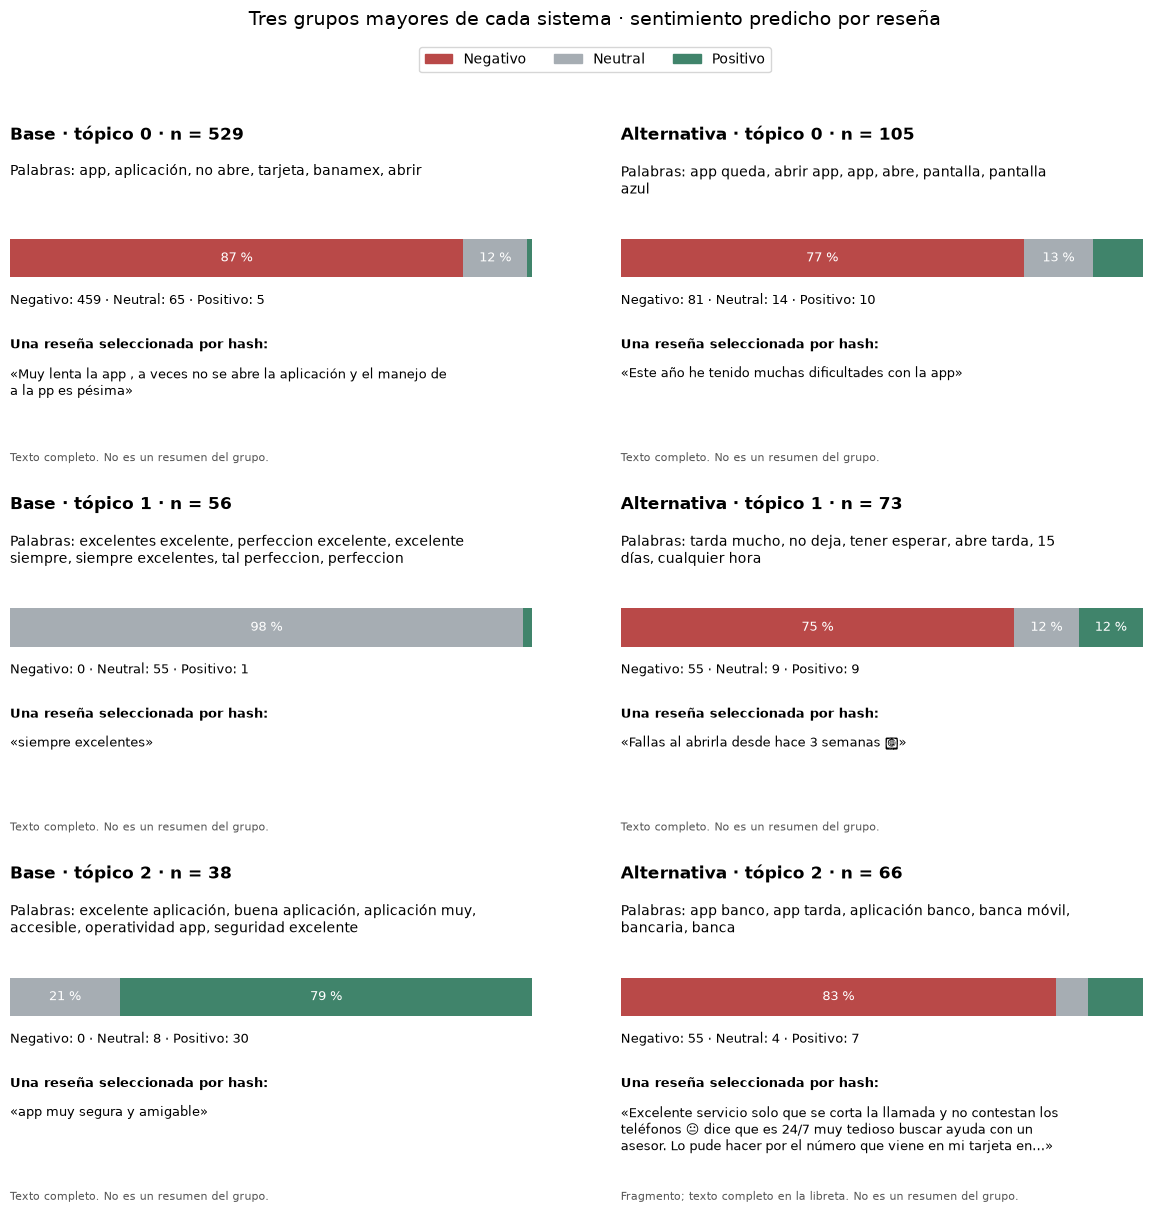

In [6]:
fig,axes=plt.subplots(3,2,figsize=(12,12))
for case in cases:
 ax=axes[case['rank']-1,0 if case['system']=='base' else 1];ax.axis('off')
 title=f"{SYSTEMS[case['system']]} · tópico {case['topic_id']} · n = {case['size']}"
 ax.text(0,1,title,weight='bold',fontsize=12,va='top',transform=ax.transAxes)
 ax.text(0,.89,textwrap.fill('Palabras: '+', '.join(case['keywords'][:6]),65),fontsize=10,va='top',transform=ax.transAxes)
 inset=ax.inset_axes([0,.56,.98,.12]);left=0
 for label in LABELS:
  value=case['sentiment'][label]/case['size']*100
  inset.barh([0],[value],left=left,color=COLORS[label])
  if value>=12:inset.text(left+value/2,0,f'{value:.0f} %',ha='center',va='center',color='white',fontsize=9)
  left+=value
 inset.set_xlim(0,100);inset.axis('off')
 ax.text(0,.52,' · '.join(f"{NAMES[l]}: {case['sentiment'][l]}" for l in LABELS),fontsize=9,va='top',transform=ax.transAxes)
 text=case['reviews'][0]['model_text'];snippet=' '.join(text.split())
 cropped=len(snippet)>190
 if cropped:snippet=snippet[:190].rstrip()+'…'
 ax.text(0,.39,'Una reseña seleccionada por hash:',weight='bold',fontsize=9,va='top',transform=ax.transAxes)
 ax.text(0,.31,textwrap.fill('«'+snippet+'»',67),fontsize=9,va='top',transform=ax.transAxes)
 ax.text(0,.03,('Fragmento; texto completo en la libreta.' if cropped else 'Texto completo.')+' No es un resumen del grupo.',fontsize=8,color='#555',va='bottom',transform=ax.transAxes)
fig.legend(handles=[Patch(color=COLORS[l],label=NAMES[l]) for l in LABELS],loc='upper center',ncol=3,bbox_to_anchor=(.5,.99))
fig.suptitle('Tres grupos mayores de cada sistema · sentimiento predicho por reseña',y=1.015,fontsize=14)
fig.tight_layout(rect=[0,0,1,.96],h_pad=1.5,w_pad=2.5)
plt.show();figures['ejemplos-topicos-sentimiento']=fig;tables['ejemplos-sentimiento-conteos']=summary;payloads['ejemplos-con-evidencia']=cases

## 5. Interpretación LLM: respuestas guardadas de ambos sistemas

Se ejecutaron los 18 tópicos base y 28 alternativos, excluyendo −1, con `google/gemini-2.5-flash`, prompt fijo `voc-topic-es-v3`, temperatura 0, salida JSON estructurada, razonamiento deshabilitado y máximo 800 tokens de salida. Se enviaron hasta seis reseñas por tópico, recortadas a 900 caracteres. La selección del productor conserva primero la evidencia guardada y completa con miembros del grupo: no es una muestra aleatoria de todas sus reseñas.

La ejecución del 7 de noviembre reemplaza el aplazamiento anterior: tres lotes de 18, 20 y 8 solicitudes, sin reintentos. La instantánea conserva solicitudes, respuestas, uso facturado, IDs de intentos y manifiestos de procedencia. No se modificaron agrupamientos ni sentimientos.

Los conteos reflejan categorías asignadas por el LLM, no validación humana de funcionalidades ni métricas de calidad de BERTopic. `unclear` es evidencia insuficiente para una capacidad; `mixed` reúne varios asuntos; un fallo técnico es otra categoría. Incluso `single_feature` puede nombrar atributos generales o reunir capacidades distintas bajo un título amplio. No interpretamos más casos de esa categoría como una mejora comprobada.

assessment,single_feature,mixed,unclear,failed,total
system,,,,,
base,6,5,7,0,18
alternative,15,8,5,0,28


,system,topic_id,size,assessment,name,proposed_feature
0,base,0,529,mixed,Problemas de acceso y visualización de movimie...,None
1,base,1,56,unclear,Calidad general de la aplicación,None
2,base,2,38,mixed,Seguridad y facilidad de uso de la aplicación,None
3,base,3,34,unclear,Funcionamiento general de la aplicación,None
4,base,4,30,mixed,Calidad del servicio y atención al cliente,None
5,base,5,30,single_feature,Facilidad de uso de la aplicación,Facilidad de uso general de la aplicación
6,base,6,30,single_feature,Mejoras en la velocidad de apertura y rendimie...,Mejora en la velocidad de apertura de la aplic...
7,base,7,28,unclear,Calidad general de la aplicación,None
8,base,8,25,unclear,Valoración positiva general de la aplicación,None
9,base,9,23,mixed,Evaluación de la experiencia del usuario con l...,None


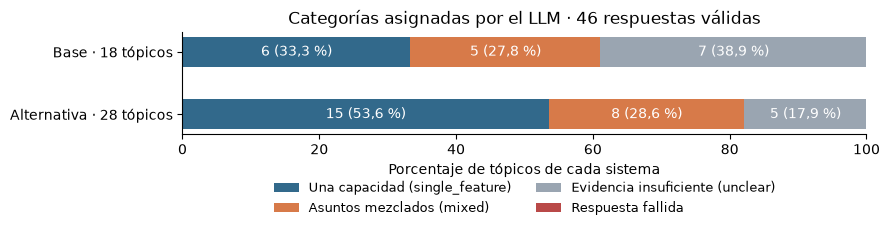

{
  "state": "completed",
  "topics_base": 18,
  "topics_alternative": 28,
  "provider_attempts": 46,
  "successful_topics": 46,
  "failed_topics": 0,
  "provider_cost_usd": "0.02877344",
  "new_requests_this_notebook": 0,
  "human_topic_quality_validation": false,
  "note": "Categorías del LLM sobre evidencia limitada, no calidad validada de los tópicos."
}


In [7]:
from hashlib import sha256
from decimal import Decimal
from voc.embeddings.contracts import canonical_json
from voc_ml.llm.topic_interpretation import normalize
snapshot_path=NB_ROOT/'sources/interpretacion-seccion-4/20261107T174441Z/evidencia.json'
assert digest(snapshot_path)=='d854dd41ddc15871df6c33130661660099096a34700cc4ed9a026ad85ac14f7a'
snapshot=json.loads(snapshot_path.read_text())
assert snapshot['receipt']['protocol_id']==protocol['protocol_id']
assert snapshot['grouping_sentiment_preserved'] is True
sources['llm_snapshot']={'path':str(snapshot_path.relative_to(REPO)),'sha256':digest(snapshot_path)}
rows=[];provider_cost=Decimal(0);attempt_ids=set()
for item in snapshot['topics']:
 record=item['record'];request=item['request'];response=item['response']
 assert sha256(canonical_json(request)).hexdigest()==record['request_fingerprint']==item['request_sha256']
 assert sha256(canonical_json(response)).hexdigest()==item['response_sha256']
 manifest=snapshot['sources'][item['analysis_id']]['manifest']
 assert manifest['artifacts'][record['request_artifact']]['sha256']==item['request_sha256']
 assert manifest['artifacts'][record['response_artifact']]['sha256']==item['response_sha256']
 if record['status']=='completed':assert normalize(response,record['evidence_ids'])==record['result']
 assert record['attempt_id'] not in attempt_ids
 attempt_ids.add(record['attempt_id'])
 provider_cost+=Decimal(str(record['provider']['usage']['cost']))
 result=record['result'] or {}
 rows.append({'system':item['system'],'topic_id':item['topic_id'],'size':item['size'],
  'status':record['status'],'assessment':result.get('assessment','failed'),
  'name':result.get('name'),'proposed_feature':result.get('proposed_feature'),
  'topic_description':result.get('topic_description'),'attempt_id':record['attempt_id'],
  'analysis_id':item['analysis_id'],'cost_usd':record['provider']['usage']['cost'],
  **item['sentiment_counts']})
interpretations=pd.DataFrame(rows)
assert len(interpretations)==len(attempt_ids)==46
assert str(provider_cost)==snapshot['total_cost_usd']
for system,expected in [('base',18),('alternative',28)]:
 part=interpretations.loc[interpretations.system.eq(system)]
 assert len(part)==expected and part.topic_id.is_unique
 assert set(part.topic_id)=={t.topic_id for t in analyses[system].topics if t.topic_id>=0}
 for row in part.itertuples():
  members=frames[system].loc[frames[system].topic_id.eq(row.topic_id)]
  assert len(members)==row.size
  assert all(int(members.model_label.eq(l).sum())==getattr(row,l) for l in LABELS)
CATEGORIES=['single_feature','mixed','unclear','failed']
CATEGORY_NAMES={'single_feature':'Una capacidad (single_feature)','mixed':'Asuntos mezclados (mixed)',
 'unclear':'Evidencia insuficiente (unclear)','failed':'Respuesta fallida'}
category_counts=pd.crosstab(interpretations.system,interpretations.assessment).reindex(index=list(SYSTEMS),columns=CATEGORIES,fill_value=0)
category_counts['total']=category_counts[CATEGORIES].sum(axis=1)
assert category_counts.total.tolist()==[18,28]
display(category_counts)
display(interpretations[['system','topic_id','size','assessment','name','proposed_feature']])
fig,ax=plt.subplots(figsize=(9,2.8))
y=np.arange(2);left=np.zeros(2)
for category,color in zip(CATEGORIES,['#32698b','#d77a49','#9aa5b1','#b94948']):
 values=category_counts[category].to_numpy();percent=values/category_counts.total.to_numpy()*100
 ax.barh(y,percent,left=left,color=color,label=CATEGORY_NAMES[category],height=.48)
 for pos,(count,width) in enumerate(zip(values,percent)):
  if count:ax.text(left[pos]+width/2,pos,f'{count} ({width:.1f} %)'.replace('.',','),ha='center',va='center',color='white',fontsize=10)
 left+=percent
ax.set(yticks=y,yticklabels=['Base · 18 tópicos','Alternativa · 28 tópicos'],xlim=(0,100),xlabel='Porcentaje de tópicos de cada sistema')
ax.invert_yaxis();ax.legend(loc='upper center',bbox_to_anchor=(.5,-.35),ncol=2,fontsize=9,frameon=False)
ax.set_title('Categorías asignadas por el LLM · 46 respuestas válidas')
fig.tight_layout();plt.show()
figures['interpretacion-categorias']=fig
tables['interpretacion-conteos']=category_counts.reset_index()
tables['interpretacion-topicos']=interpretations
status={'state':'completed','topics_base':18,'topics_alternative':28,'provider_attempts':snapshot['total_provider_attempts'],
 'successful_topics':int(interpretations.status.eq('completed').sum()),'failed_topics':int(interpretations.status.ne('completed').sum()),
 'provider_cost_usd':str(provider_cost),'new_requests_this_notebook':0,
 'human_topic_quality_validation':False,'note':'Categorías del LLM sobre evidencia limitada, no calidad validada de los tópicos.'}
payloads['interpretacion-estado']=status
payloads['alcance']={'protocol_id':protocol['protocol_id'],'model_fits':0,'llm_requests':0,
 'saved_interpretation_requests':46,'llm_source':str(snapshot_path.relative_to(REPO)),
 'example_rule':'three largest topics per system for sentiment; largest topic within each LLM category and system, ties by topic_id',
 'sentiment_unit':'whole review, not individual aspect','human_topic_quality_validation':False}
print(json.dumps(status,ensure_ascii=False,indent=2))

## 6. Ejemplos de interpretación con su evidencia

Elegimos el grupo mayor de cada categoría y sistema, con desempate por ID: seis ejemplos. No se emparejan tópicos entre sistemas. Mostramos la respuesta completa, el sentimiento de todas las reseñas del grupo y exactamente los textos enviados al LLM, señalando cuáles citó y cuáles fueron truncados. La tabla anterior permite consultar los 46 resultados.

La categoría no sustituye una revisión de utilidad: el mayor `single_feature` base describe facilidad de uso general; el mayor alternativo reúne dificultades de acceso y navegación. Estos límites se conservan, sin reclasificar manualmente las respuestas para mejorar la comparación.

In [8]:
llm_examples=[]
for system in SYSTEMS:
 for category in CATEGORIES[:-1]:
  candidates=interpretations.loc[interpretations.system.eq(system)&interpretations.assessment.eq(category)]
  if candidates.empty:continue
  row=candidates.sort_values(['size','topic_id'],ascending=[False,True]).iloc[0]
  item=next(x for x in snapshot['topics'] if x['system']==system and x['topic_id']==int(row.topic_id))
  result=item['record']['result']
  evidence=json.loads(item['request']['body']['messages'][1]['content'])['evidence']
  reviews=[dict(r,cited=r['record_id'] in result['supporting_review_ids']) for r in evidence]
  example={'system':system,'topic_id':int(row.topic_id),'size':int(row['size']),'assessment':category,
   'result':result,'sentiment':item['sentiment_counts'],'reviews_sent':reviews,
   'selection_rule':'largest topic within system and LLM category; ties by topic_id'}
  llm_examples.append(example)
  display(Markdown(f"### {SYSTEMS[system]} · tópico {row.topic_id} · {category} · n = {row['size']}"))
  display(Markdown('**Nombre del LLM:** '+result['name']))
  display(Markdown(result['topic_description']))
  display(pd.DataFrame([item['sentiment_counts']]))
  show_texts(reviews,text_column='text')
payloads['interpretacion-ejemplos']=llm_examples

### Base · tópico 5 · single_feature · n = 30

**Nombre del LLM:** Facilidad de uso de la aplicación

Los usuarios valoran la aplicación por ser fácil de usar y por permitirles encontrar la información que necesitan de manera sencilla. Destacan que es útil, rápida y simple para consultar y acceder a sus funciones.

,negative,neutral,positive
0,0,13,17


### Base · tópico 0 · mixed · n = 529

**Nombre del LLM:** Problemas de acceso y visualización de movimientos en la aplicación móvil

... (14 outputs left out)

### Alternativa · tópico 4 · unclear · n = 54

**Nombre del LLM:** Calidad de la aplicación

Las reseñas indican una percepción general muy positiva de la aplicación, con múltiples usuarios describiéndola como "excelente". Un usuario menciona que "5 sería perfecto y no existe tal perfección", lo que sugiere que, aunque la aplicación es muy buena, siempre hay margen de mejora.

,negative,neutral,positive
0,0,0,54


In [9]:
sources['review_helper']={'path':'reports/drafts/difusion/apoyo_revision.py','sha256':digest(NB_ROOT/'apoyo_revision.py')}
exported=export_bundle(NB_ROOT/'resultados-seccion-4.ipynb',figures,tables,payloads,sources,
 'Section 4 verified metrics, topic/sentiment examples and 46 saved LLM interpretations; no provider calls during notebook execution')

/workspace/vaults/sonar/code/repos/voc-difusion/reports/difusion/apoyo_validacion.py:123: UserWarning: Glyph 128078 (\N{THUMBS DOWN SIGN}) missing from font(s) DejaVu Sans.
  fig.savefig(out/f'{name}.png',dpi=180,bbox_inches='tight',facecolor='white')


Evidencia exportada: /workspace/vaults/sonar/code/repos/voc-difusion/reports/difusion/exports/resultados-seccion-4/20261107T174650702085Z


/workspace/vaults/sonar/code/repos/voc-difusion/reports/difusion/apoyo_validacion.py:124: UserWarning: Glyph 128078 (\N{THUMBS DOWN SIGN}) missing from font(s) DejaVu Sans.
  fig.savefig(out/f'{name}.pdf',bbox_inches='tight',facecolor='white')
